# Standard errors

`fdp_se` is each cell's standard error from the infinitesimal jackknife with ranger's
empirical Bayes calibration, the method of Collins et al. (2022, supplement 1.1.2), who
mapped it for four cities. The refit computes it for every cell; [the overview](overview.md#standard-errors)
describes how it differs from calling ranger's `predict(type = "se")`. This notebook shows
what the served values look like across watersheds and within one.

Code: `input-data/tensor/fdp/se_fdp.R`. Each watershed's `se.json` (quantiles, calibration)
and `se.tif` are under `s3://carbonplan-ocr/input/flood/fdp-refit/runs/noaa-200612-202512/planar/`.

In [1]:
import json

import fsspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

REFIT = 's3://carbonplan-ocr/input/flood/fdp-refit'
RUN = 'noaa-200612-202512'
HUCS = [f'{i:02d}' for i in range(1, 19)]
NAMES = {
    '01': 'New England',
    '02': 'Mid Atlantic',
    '03': 'South Atlantic-Gulf',
    '04': 'Great Lakes',
    '05': 'Ohio',
    '06': 'Tennessee',
    '07': 'Upper Mississippi',
    '08': 'Lower Mississippi',
    '09': 'Souris-Red-Rainy',
    '10': 'Missouri',
    '11': 'Arkansas-White-Red',
    '12': 'Texas-Gulf',
    '13': 'Rio Grande',
    '14': 'Upper Colorado',
    '15': 'Lower Colorado',
    '16': 'Great Basin',
    '17': 'Pacific Northwest',
    '18': 'California',
}
fs = fsspec.filesystem('s3')


def record(path):
    return json.loads(fs.cat_file(f'{REFIT}/{path}'))


BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#9aa5b1'
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)
pd.set_option('display.max_rows', 40)


rows = []
for huc in HUCS:
    se = record(f'runs/{RUN}/planar/huc{huc}/se.json')
    s = record(f'runs/{RUN}/planar/huc{huc}/summary.json')
    rows.append(
        {
            'HUC': f'{huc} {NAMES[huc]}',
            **{q: se['se_quantiles'][q] for q in ('p10', 'p50', 'p90', 'p99')},
            'negative before calibration': se['raw_negative_share'],
            'training rows': s['final']['rows'],
            'min.node.size': s['final']['min_node_size'],
            'sample.fraction': s['final']['sample_fraction'],
            'mtry': s['final']['mtry'],
        }
    )
se = pd.DataFrame(rows).set_index('HUC')

## 1. The level differs by watershed

Median standard errors run from 0.030 in Arkansas-White-Red to 0.063 in Souris-Red-Rainy.
Within a watershed the spread is narrow: p10 and p90 are 0.008–0.023 apart.

Before calibration 10–40% of cells have a negative jackknife variance; the calibration
replaces every cell's variance with its posterior mean under a prior on non-negative
variances, so each gets a positive standard error.

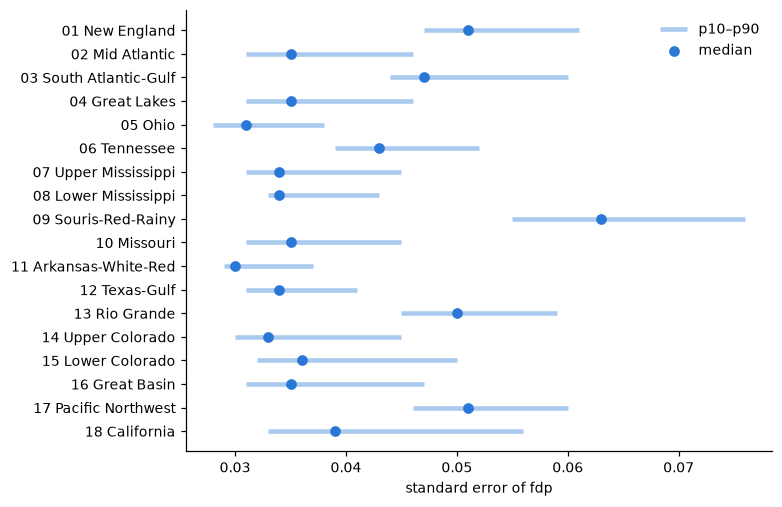

,p10,p50,p90,p99,negative before calibration,training rows,min.node.size,sample.fraction,mtry
HUC,,,,,,,,,
01 New England,0.047,0.051,0.061,0.078,0.230,"5,207",9,0.270,10
02 Mid Atlantic,0.031,0.035,0.046,0.077,0.370,"20,263",22,0.488,5
03 South Atlantic-Gulf,0.044,0.047,0.060,0.091,0.397,"17,628",14,0.513,4
04 Great Lakes,0.031,0.035,0.046,0.073,0.366,"3,875",3,0.470,2
05 Ohio,0.028,0.031,0.038,0.058,0.346,"23,408",60,0.493,6
06 Tennessee,0.039,0.043,0.052,0.066,0.125,"4,042",42,0.352,11
07 Upper Mississippi,0.031,0.034,0.045,0.074,0.365,"11,729",35,0.682,4
08 Lower Mississippi,0.033,0.034,0.043,0.068,0.099,"7,197",102,0.473,11
09 Souris-Red-Rainy,0.055,0.063,0.076,0.092,0.115,781,2,0.413,2


In [2]:
fig, ax = plt.subplots(figsize=(7, 4.5), layout='constrained')
y = np.arange(len(se))
ax.hlines(y, se['p10'], se['p90'], color=BLUE, linewidth=3, alpha=0.4, label='p10–p90')
ax.scatter(se['p50'], y, color=BLUE, zorder=3, label='median')
ax.set(yticks=y, yticklabels=se.index, xlabel='standard error of fdp')
ax.invert_yaxis()
ax.legend(frameon=False)
plt.show()
se.style.format({'training rows': '{:,}', 'min.node.size': '{:d}', 'mtry': '{:d}'}, precision=3)

In [3]:
print(
    f'median SE: {se["p50"].min():.3f} ({se["p50"].idxmin()}) to {se["p50"].max():.3f} ({se["p50"].idxmax()})'
)
print(f'p90 - p10: {(se["p90"] - se["p10"]).min():.3f} to {(se["p90"] - se["p10"]).max():.3f}')
print(
    f'negative before calibration: {se["negative before calibration"].min():.0%} to '
    f'{se["negative before calibration"].max():.0%}'
)

median SE: 0.030 (11 Arkansas-White-Red) to 0.063 (09 Souris-Red-Rainy)
p90 - p10: 0.008 to 0.023
negative before calibration: 10% to 40%


## 2. What sets the level

The jackknife measures how much the forest's prediction would move under resampling of its
training set, so it depends on the tuned settings and the training size as well as on the
data near a cell. Across the 18 watersheds the median standard error falls with
`min.node.size` (Spearman −0.49) and with the number of training rows (−0.46), and is
unrelated to `sample.fraction`. With 18 watersheds these are loose relations, but they
point the same way: tuning is chosen per watershed, so a standard error compares cells
within a watershed, not across two.

Spearman, median SE vs min.node.size: -0.49
Spearman, median SE vs training rows: -0.46
Spearman, median SE vs sample.fraction: -0.03


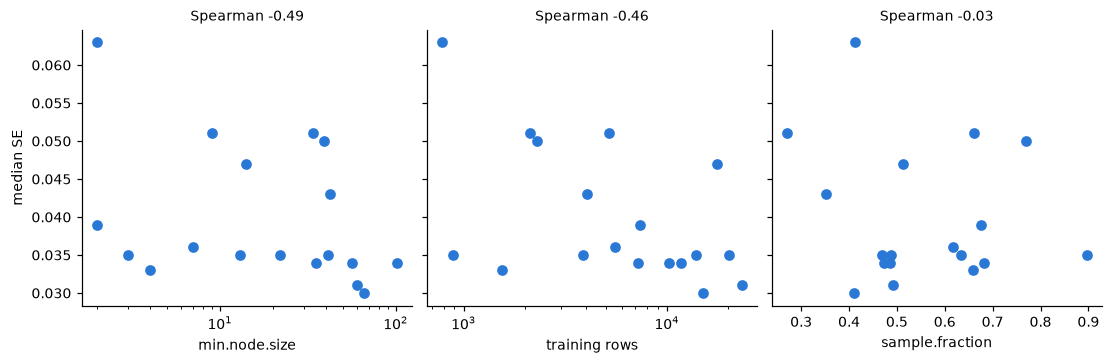

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True, layout='constrained')
for ax, col, log in zip(
    axes, ['min.node.size', 'training rows', 'sample.fraction'], [True, True, False]
):
    ax.scatter(se[col], se['p50'], color=BLUE)
    ax.set(xlabel=col, xscale='log' if log else 'linear')
    rho = se[col].corr(se['p50'], method='spearman')
    ax.set_title(f'Spearman {rho:+.2f}', fontsize=9)
    print(f'Spearman, median SE vs {col}: {rho:+.2f}')
axes[0].set_ylabel('median SE')
plt.show()

## 3. Within a watershed

In HUC 03 the standard error barely varies with the probability: its median is 0.047–0.048
in every band of `fdp`. The spread is widest in the middle bands, and above 0.8 nearly every
cell has the same value, 0.047.

In [5]:
HUC = '03'
with rasterio.open(f'{REFIT}/runs/{RUN}/planar/huc{HUC}/fdp.tif') as src:
    fdp = src.read(1)
    valid = fdp != src.nodata
with rasterio.open(f'{REFIT}/runs/{RUN}/planar/huc{HUC}/se.tif') as src:
    s = src.read(1)[valid]
fdp = fdp[valid]
band = np.minimum((fdp * 5).astype(int), 4)
bands = (
    pd.DataFrame({'band': band, 'se': s})
    .groupby('band')['se']
    .describe(percentiles=[0.1, 0.5, 0.9])
)
bands.index = [f'{b / 5:.1f}–{(b + 1) / 5:.1f}' for b in bands.index]
bands.index.name = 'fdp'
bands[['count', '10%', '50%', '90%', 'max']].style.format({'count': '{:,.0f}'}, precision=3)

,count,10%,50%,90%,max
fdp,,,,,
0.0–0.2,"2,787,416",0.045,0.047,0.052,0.151
0.2–0.4,"23,574,048",0.043,0.048,0.060,0.263
0.4–0.6,"23,207,220",0.043,0.048,0.064,0.271
0.6–0.8,"4,354,166",0.043,0.048,0.061,0.256
0.8–1.0,"13,647,061",0.047,0.047,0.047,0.132
